<a href="https://colab.research.google.com/github/DontPanic96/Data-Analyst-Portfolio/blob/main/complete_analysis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Комплексный анализ диалогов службы поддержки

Этот notebook выполняет три основные задачи:
1. **Парсинг HTML** - извлечение всех данных о клиентах и диалогах
2. **Статистический анализ** - анализ объема обращений, частотность, показатели эффективности
3. **Подготовка для AI-анализа** - форматирование данных для анализа тональности и категоризации

## Шаг 1: Установка библиотек

In [ ]:
!pip install beautifulsoup4 lxml pandas matplotlib seaborn openpyxl

## Шаг 2: Загрузка HTML файла

In [ ]:
from google.colab import files
import io

print("Загрузите HTML файл 'Выгрузка диалогов.html':")
uploaded = files.upload()

html_filename = list(uploaded.keys())[0]
print(f"✅ Загружен файл: {html_filename}")

Загрузите HTML файл 'Выгрузка диалогов.html':


Saving Выгрузка диалогов.html to Выгрузка диалогов (1).html
✅ Загружен файл: Выгрузка диалогов (1).html


## Шаг 3: Парсинг HTML и извлечение данных

### 3.1 Импорт библиотек и вспомогательные функции

In [ ]:
import re
import json
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
from typing import Dict, List, Any
from datetime import datetime, timedelta
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения графиков
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('whitegrid')

print("✅ Библиотеки импортированы")

✅ Библиотеки импортированы


### 3.2 Функции парсинга

In [ ]:
def parse_maps_from_html(html_content: str) -> Dict[str, Dict]:
    """
    Извлекает маппинги из JavaScript кода в HTML
    """
    maps = {
        'agents': {},
        'bots': {},
        'channels': {},
        'topics': {},
        'categories': {},
        'tags': {}
    }

    # Парсинг agentsMap
    agents_match = re.search(r'const agentsMap = \{([^}]+)\}', html_content)
    if agents_match:
        agents_str = agents_match.group(1)
        for match in re.finditer(r'(\d+):"([^"]+)"', agents_str):
            maps['agents'][match.group(1)] = match.group(2)

    # Парсинг botsMap
    bots_match = re.search(r'const botsMap = \{([^}]+)\}', html_content)
    if bots_match:
        bots_str = bots_match.group(1)
        for match in re.finditer(r'(\d+):"([^"]+)"', bots_str):
            maps['bots'][match.group(1)] = match.group(2)

    # Парсинг channelMap
    channels_match = re.search(r'const channelMap = \{([^}]+)\}', html_content)
    if channels_match:
        channels_str = channels_match.group(1)
        for match in re.finditer(r'(\d+):"([^"]+)"', channels_str):
            maps['channels'][match.group(1)] = match.group(2)

    # Парсинг topicMap
    topics_match = re.search(r'const topicMap = \{([^}]+)\}', html_content)
    if topics_match:
        topics_str = topics_match.group(1)
        for match in re.finditer(r'(\d+):"([^"]+)"', topics_str):
            maps['topics'][match.group(1)] = match.group(2)

    # Парсинг categoryMap
    categories_match = re.search(r'const categoryMap = \{([^}]+)\}', html_content, re.DOTALL)
    if categories_match:
        categories_str = categories_match.group(1)
        for match in re.finditer(r"(\d+):\{text:'([^']+)', color:'([^']+)'\}", categories_str):
            maps['categories'][match.group(1)] = {
                'text': match.group(2),
                'color': match.group(3)
            }

    # Парсинг tagMap
    tags_match = re.search(r'const tagMap = \{([^}]+)\}', html_content, re.DOTALL)
    if tags_match:
        tags_str = tags_match.group(1)
        for match in re.finditer(r"(\d+):\{text:'([^']+)', color:'([^']+)'\}", tags_str):
            maps['tags'][match.group(1)] = match.group(2)

    return maps


def extract_field_value(element, field_name: str, maps: Dict) -> Any:
    """
    Извлекает значение поля из HTML элемента
    """
    if not element:
        return None

    # Для ссылок извлекаем атрибут link
    if field_name in ['client_link', 'chat_link', 'crm_link', 'social_link', 'phone_number', 'email']:
        return element.get('link', '')

    # Для каналов ищем вложенный элемент channel-*
    if field_name == 'channel_name':
        channel_elem = element.find(lambda tag: tag.name and tag.name.startswith('channel-'))
        if channel_elem:
            channel_id = channel_elem.name.replace('channel-', '')
            return maps['channels'].get(channel_id, channel_id)
        return None

    # Для агентов ищем вложенный элемент agent-name-*
    if field_name == 'agent':
        agent_elem = element.find(lambda tag: tag.name and tag.name.startswith('agent-name-'))
        if agent_elem:
            agent_id = agent_elem.name.replace('agent-name-', '')
            return maps['agents'].get(agent_id, agent_id)
        return None

    # Для тем ищем вложенный элемент topic-*
    if field_name == 'topic':
        topic_elem = element.find(lambda tag: tag.name and tag.name.startswith('topic-'))
        if topic_elem:
            topic_id = topic_elem.name.replace('topic-', '')
            return maps['topics'].get(topic_id, topic_id)
        return None

    # Для категорий ищем вложенный элемент field-category-*
    if field_name == 'category':
        category_elem = element.find(lambda tag: tag.name and tag.name.startswith('field-category-'))
        if category_elem:
            category_id = category_elem.name.replace('field-category-', '')
            if category_id in maps['categories']:
                return maps['categories'][category_id]['text']
        return None

    # Для пропущенного обращения проверяем наличие элемента
    if field_name == 'chat_is_missed':
        return True if element else False

    # Для остальных полей возвращаем текстовое содержимое
    text = element.get_text(strip=True)
    return text if text else None


def parse_messages(dialog_row, maps: Dict) -> List[Dict[str, Any]]:
    """
    Парсит сообщения из диалога
    """
    messages = []

    # Находим контейнер с сообщениями
    messages_td = dialog_row.find('td', class_='dialogMessages')
    if not messages_td:
        return messages

    # Находим все элементы сообщений
    message_items = messages_td.find_all('li', class_='dialogItem')

    for item in message_items:
        # Парсим текстовые сообщения
        text_message = item.find('message-text')
        if text_message:
            sender = text_message.get('sender', '')
            time = text_message.get('time', '')
            text = text_message.get_text(strip=True)

            # Заменяем теги агентов на имена
            if '<agent-name-' in sender:
                for agent_id, agent_name in maps['agents'].items():
                    sender = sender.replace(f'<agent-name-{agent_id}/>', agent_name)
                sender = re.sub(r'<[^>]+>', '', sender)

            # Определяем роль отправителя
            role = 'agent' if sender in maps['agents'].values() else 'client'

            messages.append({
                'type': 'text',
                'sender': sender,
                'role': role,
                'time': time,
                'content': text
            })
            continue

        # Парсим медиа контент
        media_types = ['photo', 'video', 'audio', 'voice', 'document',
                       'sticker', 'location', 'contact', 'error',
                       'rich-link', 'cobrowse', 'conference', 'story']

        for media_type in media_types:
            media_elem = item.find(f'media-{media_type}')
            if media_elem:
                sender = media_elem.get('sender', '')
                time = media_elem.get('time', '')

                # Заменяем теги агентов на имена
                if '<agent-name-' in sender:
                    for agent_id, agent_name in maps['agents'].items():
                        sender = sender.replace(f'<agent-name-{agent_id}/>', agent_name)
                    sender = re.sub(r'<[^>]+>', '', sender)

                role = 'agent' if sender in maps['agents'].values() else 'client'

                messages.append({
                    'type': 'media',
                    'media_type': media_type,
                    'sender': sender,
                    'role': role,
                    'time': time,
                    'content': f'[Media: {media_type}]'
                })
                break

    return messages


def parse_dialogs(client_table, maps: Dict) -> List[Dict[str, Any]]:
    """
    Парсит все диалоги клиента
    """
    dialogs = []

    # Находим tbody с диалогами
    dialog_tbody = client_table.find('tbody', class_='dialog')
    if not dialog_tbody:
        return dialogs

    # Находим все строки диалогов
    dialog_rows = dialog_tbody.find_all('tr', class_='dialogRow')

    for dialog_row in dialog_rows:
        dialog_data = {}

        # Парсим информацию о диалоге (левая колонка)
        dialog_info_td = dialog_row.find('td', class_='dialogInfo')
        if dialog_info_td:
            # Дата начала диалога
            start_elem = dialog_info_td.find('field-start-dialog')
            if start_elem:
                dialog_data['start_dialog'] = start_elem.get_text(strip=True)

            # Ожидание ответа
            waiting_elem = dialog_info_td.find('field-first-waiting')
            if waiting_elem:
                dialog_data['first_waiting'] = waiting_elem.get_text(strip=True)

            # Длительность
            duration_elem = dialog_info_td.find('field-duration')
            if duration_elem:
                dialog_data['duration'] = duration_elem.get_text(strip=True)

            # Агент
            agent_elem = dialog_info_td.find('field-agent')
            if agent_elem:
                dialog_data['agent'] = extract_field_value(agent_elem, 'agent', maps)

            # Ссылка на диалог
            link_elem = dialog_info_td.find('field-chat-link')
            if link_elem:
                dialog_data['chat_link'] = link_elem.get('link', '')

        # Парсим сообщения диалога
        dialog_data['messages'] = parse_messages(dialog_row, maps)
        dialog_data['messages_count'] = len(dialog_data['messages'])

        # Подсчет сообщений от клиента и агента
        client_messages = [m for m in dialog_data['messages'] if m['role'] == 'client']
        agent_messages = [m for m in dialog_data['messages'] if m['role'] == 'agent']

        dialog_data['client_messages_count'] = len(client_messages)
        dialog_data['agent_messages_count'] = len(agent_messages)

        dialogs.append(dialog_data)

    return dialogs


def parse_client(client_table, maps: Dict) -> Dict[str, Any]:
    """
    Парсит данные одного клиента из таблицы
    """
    client_data = {}

    # Список полей для парсинга
    fields = [
        'client_id', 'client_name', 'channel_name', 'client_link',
        'count_dialog', 'count_visits', 'start_dialog', 'first_waiting',
        'duration', 'rating_comment', 'chat_link', 'tags',
        'phone_number', 'email', 'crm_link', 'social_link',
        'custom_data', 'commentary', 'geo_ip', 'utm',
        'agent', 'navigation_history', 'topic', 'chat_is_missed',
        'client_attribute', 'category'
    ]

    # Извлекаем значения полей
    for field in fields:
        field_tag = field.replace('_', '-')
        element = client_table.find(f'field-{field_tag}')
        value = extract_field_value(element, field, maps)
        if value is not None:
            client_data[field] = value

    # Дополнительно парсим атрибуты клиента
    client_attributes = []
    for attr_elem in client_table.find_all('client-attribute'):
        attr_name = attr_elem.get('attributename', '')
        attr_value = attr_elem.get_text(strip=True)
        if attr_name:
            client_attributes.append({
                'name': attr_name,
                'value': attr_value
            })

    if client_attributes:
        client_data['client_attributes'] = client_attributes

    # Парсим теги
    tags = []
    for tag_elem in client_table.find_all(lambda tag: tag.name and tag.name.startswith('tag-name-')):
        tag_id = tag_elem.name.replace('tag-name-', '')
        tags.append(maps['tags'].get(tag_id, tag_id))

    if tags:
        client_data['tags'] = tags

    # Парсим оценку
    for rating_elem in client_table.find_all(lambda tag: tag.name and tag.name.startswith('field-rating-')):
        rating_type = rating_elem.name.replace('field-rating-', '')
        rating_map = {
            'good': 'Очень хорошо',
            'bad': 'Очень плохо',
            'goodnormal': 'Хорошо',
            'normal': 'Нормально',
            'badnormal': 'Плохо'
        }
        client_data['rating'] = rating_map.get(rating_type, rating_type)

    # Парсим диалоги с сообщениями
    client_data['dialogs'] = parse_dialogs(client_table, maps)
    client_data['total_dialogs'] = len(client_data['dialogs'])

    # Подсчитываем общее количество сообщений
    total_messages = sum(dialog.get('messages_count', 0) for dialog in client_data['dialogs'])
    client_data['total_messages'] = total_messages

    # Подсчет сообщений по ролям
    total_client_messages = sum(dialog.get('client_messages_count', 0) for dialog in client_data['dialogs'])
    total_agent_messages = sum(dialog.get('agent_messages_count', 0) for dialog in client_data['dialogs'])

    client_data['total_client_messages'] = total_client_messages
    client_data['total_agent_messages'] = total_agent_messages

    return client_data


def parse_html_file(file_path: str) -> List[Dict[str, Any]]:
    """
    Основная функция для парсинга HTML файла
    """
    print(f"Чтение файла: {file_path}")

    # Читаем HTML файл
    with open(file_path, 'r', encoding='utf-8') as f:
        html_content = f.read()

    print("Парсинг HTML...")

    # Извлекаем маппинги
    maps = parse_maps_from_html(html_content)
    print(f"Найдено маппингов: agents={len(maps['agents'])}, "
          f"channels={len(maps['channels'])}, topics={len(maps['topics'])}, tags={len(maps['tags'])}")

    # Парсим HTML
    soup = BeautifulSoup(html_content, 'html.parser')

    # Находим все таблицы с классом "client"
    client_tables = soup.find_all('table', class_='client')
    print(f"Найдено клиентов: {len(client_tables)}")

    # Парсим каждого клиента
    clients_data = []
    for i, client_table in enumerate(client_tables, 1):
        if i % 100 == 0:
            print(f"Обработано клиентов: {i}/{len(client_tables)}")

        client_data = parse_client(client_table, maps)
        clients_data.append(client_data)

    print(f"✅ Парсинг завершен. Всего клиентов: {len(clients_data)}")

    return clients_data


print("✅ Функции парсинга загружены")

✅ Функции парсинга загружены


### 3.3 Запуск парсинга

In [ ]:
# Парсим HTML файл
clients_data = parse_html_file(html_filename)

print(f"\n✅ Успешно обработано {len(clients_data)} клиентов")
print(f"Всего диалогов: {sum(c.get('total_dialogs', 0) for c in clients_data)}")
print(f"Всего сообщений: {sum(c.get('total_messages', 0) for c in clients_data)}")

Чтение файла: Выгрузка диалогов (1).html
Парсинг HTML...
Найдено маппингов: agents=3, channels=6, topics=1, tags=0
Найдено клиентов: 2154
Обработано клиентов: 100/2154
Обработано клиентов: 200/2154
Обработано клиентов: 300/2154
Обработано клиентов: 400/2154
Обработано клиентов: 500/2154
Обработано клиентов: 600/2154
Обработано клиентов: 700/2154
Обработано клиентов: 800/2154
Обработано клиентов: 900/2154
Обработано клиентов: 1000/2154
Обработано клиентов: 1100/2154
Обработано клиентов: 1200/2154
Обработано клиентов: 1300/2154
Обработано клиентов: 1400/2154
Обработано клиентов: 1500/2154
Обработано клиентов: 1600/2154
Обработано клиентов: 1700/2154
Обработано клиентов: 1800/2154
Обработано клиентов: 1900/2154
Обработано клиентов: 2000/2154
Обработано клиентов: 2100/2154
✅ Парсинг завершен. Всего клиентов: 2154

✅ Успешно обработано 2154 клиентов
Всего диалогов: 2595
Всего сообщений: 21476


### 3.4 Просмотр примера данных

In [ ]:
# Выводим пример первого клиента
if clients_data:
    first_client = clients_data[0]
    print("Пример данных первого клиента:")
    print("="*80)
    print(f"ID: {first_client.get('client_id')}")
    print(f"Имя: {first_client.get('client_name')}")
    print(f"Email: {first_client.get('email')}")
    print(f"Канал: {first_client.get('channel_name')}")
    print(f"Агент: {first_client.get('agent')}")
    print(f"Всего диалогов: {first_client.get('total_dialogs')}")
    print(f"Всего сообщений: {first_client.get('total_messages')}")

    if first_client.get('dialogs'):
        first_dialog = first_client['dialogs'][0]
        print(f"\nПервый диалог:")
        print(f"  Дата: {first_dialog.get('start_dialog')}")
        print(f"  Время ожидания: {first_dialog.get('first_waiting')}")
        print(f"  Длительность: {first_dialog.get('duration')}")
        print(f"  Сообщений: {first_dialog.get('messages_count')}")

        if first_dialog.get('messages'):
            print(f"\n  Первые 3 сообщения:")
            for i, msg in enumerate(first_dialog['messages'][:3], 1):
                print(f"\n  [{i}] {msg['time']} - {msg['sender']} ({msg['role']}):")
                content = msg['content'][:100] + '...' if len(msg['content']) > 100 else msg['content']
                print(f"      {content}")

Пример данных первого клиента:
ID: 2158
Имя: Вероника
Email: firverons@gmail.com
Канал: Support
Агент: Tessa
Всего диалогов: 1
Всего сообщений: 22

Первый диалог:
  Дата: 08.12.2025 14:10:02
  Время ожидания: None
  Длительность: None
  Сообщений: 22

  Первые 3 сообщения:

  [1] 14:10:02 - Вероника (client):
      Здраствуйте, подскажите пожалуйста, почему резко испортилось качество загружаемых фото для древа на ...

  [2] 14:10:54 - Tessa (agent):
      Здравствуйте 😊 Переработали систему загрузки фото, чтобы не было ограничений по весу. Можетеч пожалу...

  [3] 14:11:07 - Вероника (client):
      [Media: photo]


## Шаг 4: Статистический анализ данных

### 4.1 Общая статистика

In [ ]:
def calculate_general_statistics(clients_data: List[Dict]) -> Dict:
    """
    Расчет общей статистики по обращениям
    """
    total_clients = len(clients_data)
    total_dialogs = sum(c.get('total_dialogs', 0) for c in clients_data)
    total_messages = sum(c.get('total_messages', 0) for c in clients_data)
    total_client_messages = sum(c.get('total_client_messages', 0) for c in clients_data)
    total_agent_messages = sum(c.get('total_agent_messages', 0) for c in clients_data)

    # Клиенты с email
    clients_with_email = sum(1 for c in clients_data if c.get('email'))

    # Пропущенные обращения
    missed_chats = sum(1 for c in clients_data if c.get('chat_is_missed'))

    # Обращения с оценкой
    rated_chats = sum(1 for c in clients_data if c.get('rating'))

    # Статистика по оценкам
    ratings = [c.get('rating') for c in clients_data if c.get('rating')]
    rating_counts = Counter(ratings)

    stats = {
        'total_clients': total_clients,
        'total_dialogs': total_dialogs,
        'total_messages': total_messages,
        'total_client_messages': total_client_messages,
        'total_agent_messages': total_agent_messages,
        'avg_messages_per_dialog': round(total_messages / total_dialogs, 2) if total_dialogs > 0 else 0,
        'avg_dialogs_per_client': round(total_dialogs / total_clients, 2) if total_clients > 0 else 0,
        'clients_with_email': clients_with_email,
        'clients_with_email_pct': round(clients_with_email / total_clients * 100, 2) if total_clients > 0 else 0,
        'missed_chats': missed_chats,
        'missed_chats_pct': round(missed_chats / total_clients * 100, 2) if total_clients > 0 else 0,
        'rated_chats': rated_chats,
        'rated_chats_pct': round(rated_chats / total_clients * 100, 2) if total_clients > 0 else 0,
        'rating_distribution': dict(rating_counts)
    }

    return stats


# Расчет общей статистики
general_stats = calculate_general_statistics(clients_data)

print("="*80)
print("ОБЩАЯ СТАТИСТИКА ПО ОБРАЩЕНИЯМ")
print("="*80)
print(f"\nВсего клиентов: {general_stats['total_clients']:,}")
print(f"Всего диалогов: {general_stats['total_dialogs']:,}")
print(f"Всего сообщений: {general_stats['total_messages']:,}")
print(f"  - От клиентов: {general_stats['total_client_messages']:,}")
print(f"  - От агентов: {general_stats['total_agent_messages']:,}")

print(f"\nСреднее количество:")
print(f"  - Диалогов на клиента: {general_stats['avg_dialogs_per_client']}")
print(f"  - Сообщений на диалог: {general_stats['avg_messages_per_dialog']}")

print(f"\nКонтактная информация:")
print(f"  - Клиентов с email: {general_stats['clients_with_email']} ({general_stats['clients_with_email_pct']}%)")

print(f"\nПропущенные обращения: {general_stats['missed_chats']} ({general_stats['missed_chats_pct']}%)")

print(f"\nОценки клиентов:")
print(f"  - Всего оценок: {general_stats['rated_chats']} ({general_stats['rated_chats_pct']}%)")
if general_stats['rating_distribution']:
    print(f"  - Распределение:")
    for rating, count in sorted(general_stats['rating_distribution'].items(), key=lambda x: x[1], reverse=True):
        print(f"    • {rating}: {count}")

ОБЩАЯ СТАТИСТИКА ПО ОБРАЩЕНИЯМ

Всего клиентов: 2,154
Всего диалогов: 2,595
Всего сообщений: 21,476
  - От клиентов: 11,136
  - От агентов: 10,340

Среднее количество:
  - Диалогов на клиента: 1.2
  - Сообщений на диалог: 8.28

Контактная информация:
  - Клиентов с email: 1756 (81.52%)

Пропущенные обращения: 197 (9.15%)

Оценки клиентов:
  - Всего оценок: 121 (5.62%)
  - Распределение:
    • Очень хорошо: 83
    • comment: 36
    • Очень плохо: 2


### 4.2 Статистика по временным периодам

In [ ]:
def parse_datetime(date_str: str) -> datetime:
    """
    Парсит дату из строки формата "DD.MM.YYYY HH:MM:SS"
    """
    try:
        return datetime.strptime(date_str, '%d.%m.%Y %H:%M:%S')
    except:
        return None


def analyze_temporal_patterns(clients_data: List[Dict]) -> Dict:
    """
    Анализ временных паттернов обращений
    """
    # Собираем все диалоги с датами
    all_dialogs = []
    for client in clients_data:
        for dialog in client.get('dialogs', []):
            if dialog.get('start_dialog'):
                dt = parse_datetime(dialog['start_dialog'])
                if dt:
                    all_dialogs.append({
                        'datetime': dt,
                        'client_id': client.get('client_id'),
                        'agent': dialog.get('agent'),
                        'messages_count': dialog.get('messages_count', 0)
                    })

    # Создаем DataFrame для анализа
    df = pd.DataFrame(all_dialogs)
    df['date'] = df['datetime'].dt.date
    df['year'] = df['datetime'].dt.year
    df['month'] = df['datetime'].dt.month
    df['year_month'] = df['datetime'].dt.to_period('M')
    df['day_of_week'] = df['datetime'].dt.day_name()
    df['hour'] = df['datetime'].dt.hour

    # Статистика по месяцам
    monthly_stats = df.groupby('year_month').agg({
        'datetime': 'count',
        'messages_count': 'sum'
    }).rename(columns={'datetime': 'dialogs_count', 'messages_count': 'total_messages'})

    # Статистика по дням недели
    day_stats = df.groupby('day_of_week').size().to_dict()

    # Статистика по часам
    hour_stats = df.groupby('hour').size().to_dict()

    return {
        'dataframe': df,
        'monthly_stats': monthly_stats,
        'day_stats': day_stats,
        'hour_stats': hour_stats
    }


# Анализ временных паттернов
temporal_analysis = analyze_temporal_patterns(clients_data)
df_dialogs = temporal_analysis['dataframe']

print("="*80)
print("СТАТИСТИКА ПО ВРЕМЕННЫМ ПЕРИОДАМ")
print("="*80)

print("\nСтатистика по месяцам:")
print(temporal_analysis['monthly_stats'].to_string())

print("\n\nРаспределение по дням недели:")
for day, count in sorted(temporal_analysis['day_stats'].items(), key=lambda x: x[1], reverse=True):
    print(f"  {day}: {count} обращений")

СТАТИСТИКА ПО ВРЕМЕННЫМ ПЕРИОДАМ

Статистика по месяцам:
            dialogs_count  total_messages
year_month                               
2024-01               100            1254
2024-02                68             875
2024-03                84             781
2024-04                81             643
2024-05                69             624
2024-06                88             683
2024-07                90             807
2024-08               108             999
2024-09                74             653
2024-10                66             566
2024-11                91             792
2024-12                58             644
2025-01                70             699
2025-02                87             934
2025-03               153            1605
2025-04               114             985
2025-05               171            1317
2025-06               115             864
2025-07               217            1388
2025-08               193            1057
2025-09            

### 4.3 Визуализация статистики

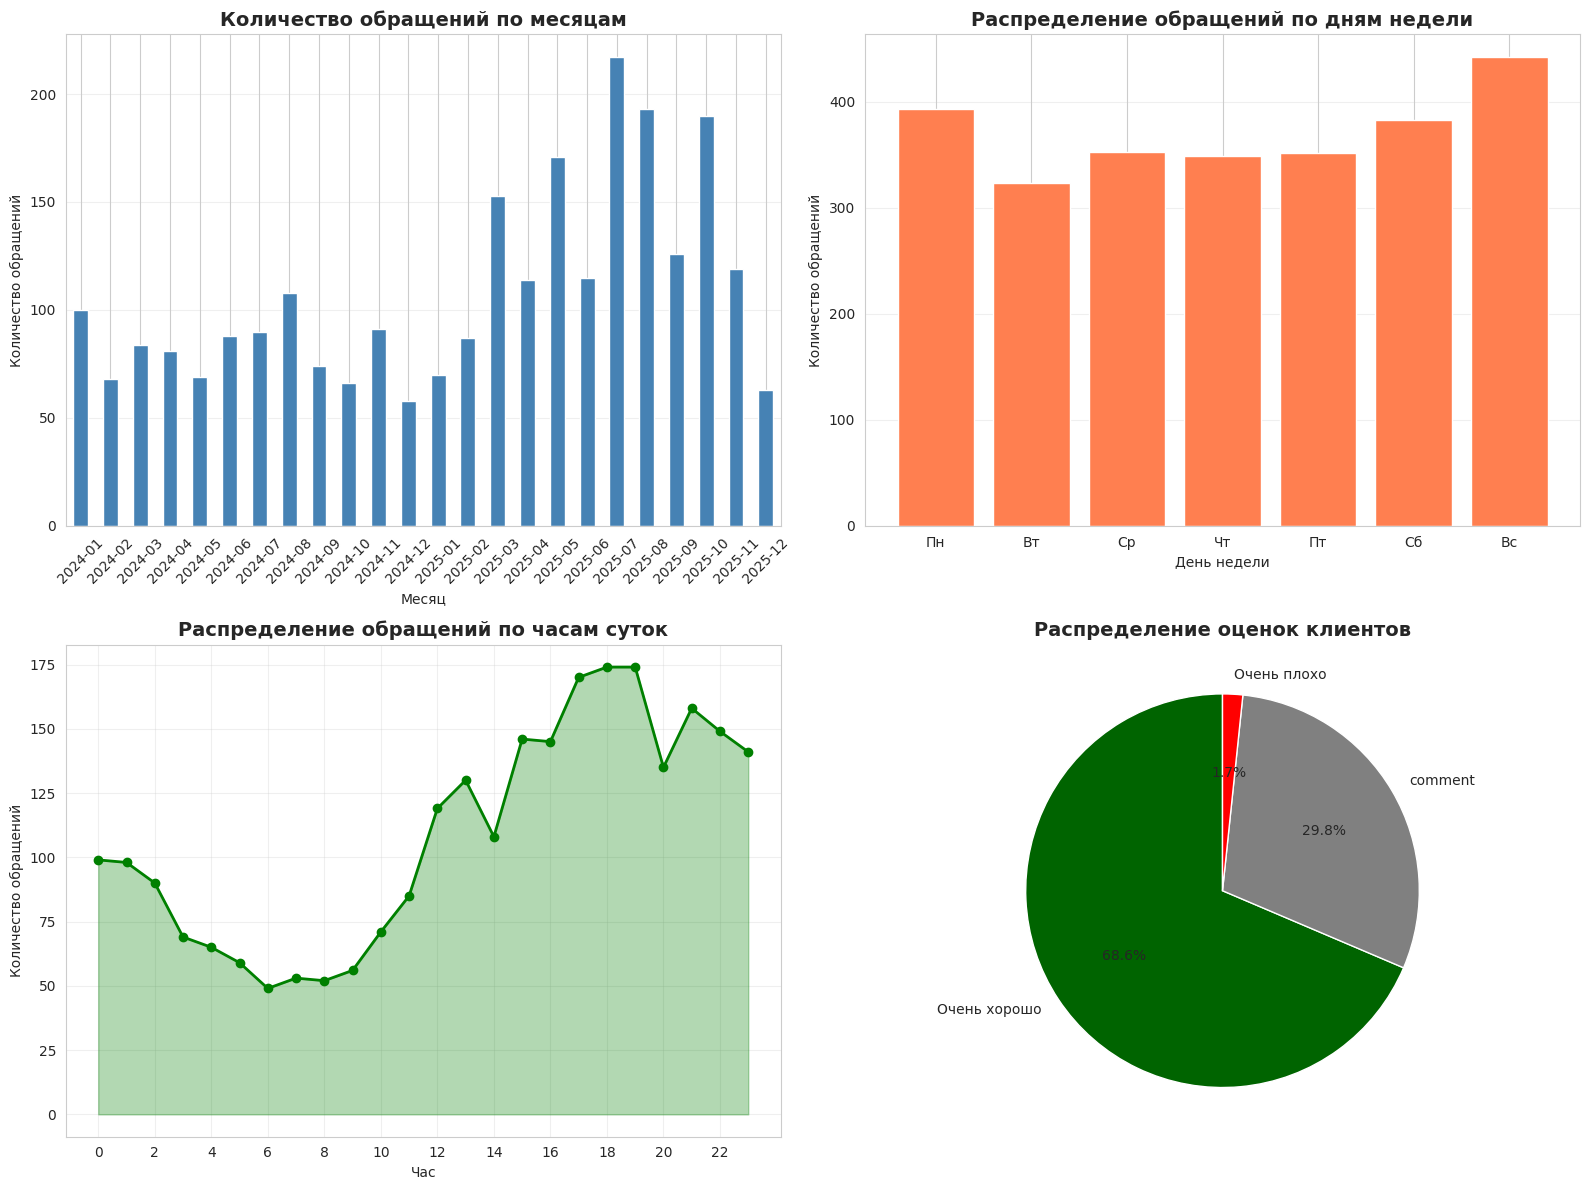

✅ Графики сохранены в файл: statistics_visualization.png


In [ ]:
# График обращений по месяцам
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Обращения по месяцам
monthly_data = temporal_analysis['monthly_stats']
ax1 = axes[0, 0]
monthly_data['dialogs_count'].plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Количество обращений по месяцам', fontsize=14, fontweight='bold')
ax1.set_xlabel('Месяц')
ax1.set_ylabel('Количество обращений')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', alpha=0.3)

# 2. Распределение по дням недели
ax2 = axes[0, 1]
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = [temporal_analysis['day_stats'].get(day, 0) for day in day_order]
day_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
ax2.bar(day_labels, day_counts, color='coral')
ax2.set_title('Распределение обращений по дням недели', fontsize=14, fontweight='bold')
ax2.set_xlabel('День недели')
ax2.set_ylabel('Количество обращений')
ax2.grid(axis='y', alpha=0.3)

# 3. Распределение по часам
ax3 = axes[1, 0]
hours = sorted(temporal_analysis['hour_stats'].keys())
hour_counts = [temporal_analysis['hour_stats'][h] for h in hours]
ax3.plot(hours, hour_counts, marker='o', color='green', linewidth=2)
ax3.fill_between(hours, hour_counts, alpha=0.3, color='green')
ax3.set_title('Распределение обращений по часам суток', fontsize=14, fontweight='bold')
ax3.set_xlabel('Час')
ax3.set_ylabel('Количество обращений')
ax3.set_xticks(range(0, 24, 2))
ax3.grid(alpha=0.3)

# 4. Распределение оценок
ax4 = axes[1, 1]
if general_stats['rating_distribution']:
    ratings = list(general_stats['rating_distribution'].keys())
    counts = list(general_stats['rating_distribution'].values())
    colors_map = {
        'Очень хорошо': 'darkgreen',
        'Хорошо': 'lightgreen',
        'Нормально': 'gold',
        'Плохо': 'orange',
        'Очень плохо': 'red'
    }
    colors = [colors_map.get(r, 'gray') for r in ratings]
    ax4.pie(counts, labels=ratings, autopct='%1.1f%%', colors=colors, startangle=90)
    ax4.set_title('Распределение оценок клиентов', fontsize=14, fontweight='bold')
else:
    ax4.text(0.5, 0.5, 'Нет данных об оценках', ha='center', va='center', fontsize=12)
    ax4.axis('off')

plt.tight_layout()
plt.savefig('statistics_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Графики сохранены в файл: statistics_visualization.png")

### 4.4 Статистика по агентам

In [ ]:
def analyze_agent_performance(clients_data: List[Dict]) -> pd.DataFrame:
    """
    Анализ эффективности работы агентов
    """
    agent_stats = defaultdict(lambda: {
        'dialogs_count': 0,
        'messages_count': 0,
        'clients_count': set(),
        'ratings': []
    })

    for client in clients_data:
        agent = client.get('agent')
        if agent:
            agent_stats[agent]['dialogs_count'] += client.get('total_dialogs', 0)
            agent_stats[agent]['messages_count'] += client.get('total_agent_messages', 0)
            agent_stats[agent]['clients_count'].add(client.get('client_id'))

            if client.get('rating'):
                agent_stats[agent]['ratings'].append(client.get('rating'))

    # Формируем DataFrame
    data = []
    for agent, stats in agent_stats.items():
        data.append({
            'Агент': agent,
            'Кол-во диалогов': stats['dialogs_count'],
            'Кол-во сообщений': stats['messages_count'],
            'Уникальных клиентов': len(stats['clients_count']),
            'Получено оценок': len(stats['ratings']),
            'Средняя длина диалога (сообщений)': round(stats['messages_count'] / stats['dialogs_count'], 2) if stats['dialogs_count'] > 0 else 0
        })

    df = pd.DataFrame(data).sort_values('Кол-во диалогов', ascending=False)
    return df


# Анализ работы агентов
agent_performance = analyze_agent_performance(clients_data)

print("="*80)
print("СТАТИСТИКА ПО АГЕНТАМ")
print("="*80)
print(agent_performance.to_string(index=False))

СТАТИСТИКА ПО АГЕНТАМ
       Агент  Кол-во диалогов  Кол-во сообщений  Уникальных клиентов  Получено оценок  Средняя длина диалога (сообщений)
       Tessa             1555              5953                 1255              118                               3.83
        Alex              574              2246                  495                2                               3.91
Alex Support              368              2065                  315                1                               5.61
           0               98                76                   89                0                               0.78


### 4.5 Статистика по каналам

In [ ]:
def analyze_channels(clients_data: List[Dict]) -> pd.DataFrame:
    """
    Анализ обращений по каналам
    """
    channel_stats = Counter()

    for client in clients_data:
        channel = client.get('channel_name')
        if channel:
            channel_stats[channel] += 1

    total = sum(channel_stats.values())
    data = []
    for channel, count in channel_stats.most_common():
        data.append({
            'Канал': channel,
            'Количество обращений': count,
            'Процент': round(count / total * 100, 2) if total > 0 else 0
        })

    return pd.DataFrame(data)


# Анализ каналов
channel_analysis = analyze_channels(clients_data)

print("="*80)
print("СТАТИСТИКА ПО КАНАЛАМ ОБРАЩЕНИЙ")
print("="*80)
print(channel_analysis.to_string(index=False))

СТАТИСТИКА ПО КАНАЛАМ ОБРАЩЕНИЙ
                                   Канал  Количество обращений  Процент
                                 Support                  2143    99.49
                              Creator LK                     4     0.19
            deasoft.ru (удаленный канал)                     4     0.19
   app.thesimstree.com (удаленный канал)                     1     0.05
              TEST API (удаленный канал)                     1     0.05
ThesimsTreeSupport_bot (удаленный канал)                     1     0.05


### 4.6 Сохранение статистики в Excel

In [ ]:
# Сохраняем все статистики в Excel файл
with pd.ExcelWriter('statistics_report.xlsx', engine='openpyxl') as writer:
    # Общая статистика
    pd.DataFrame([general_stats]).T.to_excel(writer, sheet_name='Общая статистика')

    # Месячная статистика
    temporal_analysis['monthly_stats'].to_excel(writer, sheet_name='По месяцам')

    # Статистика по агентам
    agent_performance.to_excel(writer, sheet_name='По агентам', index=False)

    # Статистика по каналам
    channel_analysis.to_excel(writer, sheet_name='По каналам', index=False)

print("✅ Статистический отчет сохранен в файл: statistics_report.xlsx")

✅ Статистический отчет сохранен в файл: statistics_report.xlsx


## Шаг 5: Подготовка данных для AI-анализа

### 5.1 Форматирование диалогов для анализа тональности

In [ ]:
def prepare_dialogues_for_sentiment_analysis(clients_data: List[Dict]) -> List[Dict]:
    """
    Подготовка диалогов в формате для анализа тональности с помощью LLM
    """
    prepared_dialogues = []

    for client in clients_data:
        client_id = client.get('client_id')
        client_name = client.get('client_name')
        client_email = client.get('email')
        channel = client.get('channel_name')
        agent = client.get('agent')
        rating = client.get('rating')
        rating_comment = client.get('rating_comment')

        for dialog_idx, dialog in enumerate(client.get('dialogs', []), 1):
            # Формируем текст диалога
            conversation = []
            client_messages_text = []
            agent_messages_text = []

            for msg in dialog.get('messages', []):
                if msg['type'] == 'text':
                    conversation.append(f"{msg['role'].upper()} [{msg['time']}]: {msg['content']}")

                    if msg['role'] == 'client':
                        client_messages_text.append(msg['content'])
                    else:
                        agent_messages_text.append(msg['content'])
                else:
                    conversation.append(f"{msg['role'].upper()} [{msg['time']}]: {msg['content']}")

            # Объединяем все сообщения
            full_conversation = "\n".join(conversation)
            client_text_combined = " ".join(client_messages_text)
            agent_text_combined = " ".join(agent_messages_text)

            dialogue_data = {
                'dialogue_id': f"{client_id}_dialog_{dialog_idx}",
                'client_id': client_id,
                'client_name': client_name,
                'client_email': client_email,
                'channel': channel,
                'agent': dialog.get('agent', agent),
                'start_datetime': dialog.get('start_dialog'),
                'duration': dialog.get('duration'),
                'first_waiting_time': dialog.get('first_waiting'),
                'messages_count': dialog.get('messages_count', 0),
                'client_messages_count': dialog.get('client_messages_count', 0),
                'agent_messages_count': dialog.get('agent_messages_count', 0),
                'rating': rating,
                'rating_comment': rating_comment,
                'full_conversation': full_conversation,
                'client_text_combined': client_text_combined,
                'agent_text_combined': agent_text_combined,
                'chat_link': dialog.get('chat_link')
            }

            prepared_dialogues.append(dialogue_data)

    return prepared_dialogues


# Подготовка диалогов
prepared_dialogues = prepare_dialogues_for_sentiment_analysis(clients_data)

print(f"✅ Подготовлено {len(prepared_dialogues)} диалогов для анализа")
print(f"\nПример подготовленного диалога:")
print("="*80)
if prepared_dialogues:
    example = prepared_dialogues[0]
    print(f"ID диалога: {example['dialogue_id']}")
    print(f"Клиент: {example['client_name']} ({example['client_email']})")
    print(f"Агент: {example['agent']}")
    print(f"Дата: {example['start_datetime']}")
    print(f"Длительность: {example['duration']}")
    print(f"Сообщений: {example['messages_count']} (клиент: {example['client_messages_count']}, агент: {example['agent_messages_count']})")
    print(f"\nПолный диалог:\n{example['full_conversation'][:500]}...")

✅ Подготовлено 2595 диалогов для анализа

Пример подготовленного диалога:
ID диалога: 2158_dialog_1
Клиент: Вероника (firverons@gmail.com)
Агент: Tessa
Дата: 08.12.2025 14:10:02
Длительность: None
Сообщений: 22 (клиент: 13, агент: 9)

Полный диалог:
CLIENT [14:10:02]: Здраствуйте, подскажите пожалуйста, почему резко испортилось качество загружаемых фото для древа на сайт? Загружаю хорошее качество, как раньше, а при просмотре все урезается в пиксели
AGENT [14:10:54]: Здравствуйте 😊 Переработали систему загрузки фото, чтобы не было ограничений по весу. Можетеч пожалуйста, скинуть примеры
CLIENT [14:11:07]: [Media: photo]
CLIENT [14:11:09]: [Media: photo]
AGENT [14:11:35]: Именно на аватарах такая проблема?
AGENT [14:11:41]: Мне нужно видеть ...


### 5.2 Создание промптов для LLM анализа

In [ ]:
def create_llm_analysis_prompts(dialogue_data: Dict) -> Dict[str, str]:
    """
    Создает промпты для различных типов анализа диалога с помощью LLM
    """
    prompts = {}

    # 1. Анализ тональности клиента
    prompts['client_sentiment'] = f"""Проанализируй тональность сообщений КЛИЕНТА в следующем диалоге со службой поддержки.

Диалог:
{dialogue_data['full_conversation']}

Оцени тональность клиента по шкале:
- Очень позитивная
- Позитивная
- Нейтральная
- Негативная
- Очень негативная

Также укажи:
1. Эмоциональное состояние клиента (спокойный, раздраженный, благодарный, недовольный и т.д.)
2. Ключевые фразы, указывающие на эмоции
3. Изменение тональности в процессе диалога (если есть)

Формат ответа (JSON):
{{
  "sentiment": "...",
  "emotional_state": "...",
  "key_phrases": [...],
  "sentiment_change": "..."
}}"""

    # 2. Анализ тональности агента
    prompts['agent_sentiment'] = f"""Проанализируй тональность и качество обслуживания АГЕНТА в следующем диалоге.

Диалог:
{dialogue_data['full_conversation']}

Оцени:
1. Тональность агента (профессиональная, дружелюбная, формальная, безразличная)
2. Эмпатия (высокая, средняя, низкая)
3. Оперативность ответов
4. Полезность информации
5. Вежливость

Формат ответа (JSON):
{{
  "tone": "...",
  "empathy_level": "...",
  "responsiveness": "...",
  "helpfulness": "...",
  "politeness": "...",
  "strengths": [...],
  "areas_for_improvement": [...]
}}"""

    # 3. Категоризация обращения
    prompts['categorization'] = f"""Категоризируй следующее обращение клиента в службу поддержки.

Диалог:
{dialogue_data['full_conversation']}

Определи:
1. Тип обращения (технический вопрос, жалоба, запрос информации, проблема с оплатой, ошибка в работе, запрос функции, другое)
2. Приоритет (высокий, средний, низкий)
3. Категория продукта/услуги (если применимо)
4. Проблема решена? (да/нет/частично)
5. Требуется ли эскалация?

Формат ответа (JSON):
{{
  "issue_type": "...",
  "priority": "...",
  "category": "...",
  "resolved": "...",
  "escalation_needed": true/false,
  "summary": "...",
  "keywords": [...]
}}"""

    # 4. Общий анализ качества диалога
    prompts['quality_analysis'] = f"""Проанализируй качество следующего диалога со службой поддержки.

Информация о диалоге:
- Длительность: {dialogue_data['duration']}
- Время ожидания первого ответа: {dialogue_data['first_waiting_time']}
- Количество сообщений: {dialogue_data['messages_count']}
- Оценка клиента: {dialogue_data['rating'] or 'не указана'}
{f"- Комментарий: {dialogue_data['rating_comment']}" if dialogue_data['rating_comment'] else ''}

Диалог:
{dialogue_data['full_conversation']}

Оцени:
1. Общее качество обслуживания (1-10)
2. Эффективность решения проблемы (1-10)
3. Коммуникативные навыки агента (1-10)
4. Удовлетворенность клиента (1-10)
5. Ключевые моменты диалога (положительные и отрицательные)
6. Рекомендации по улучшению

Формат ответа (JSON):
{{
  "service_quality_score": 0-10,
  "problem_resolution_score": 0-10,
  "communication_score": 0-10,
  "customer_satisfaction_score": 0-10,
  "positive_moments": [...],
  "negative_moments": [...],
  "recommendations": [...]
}}"""

    return prompts


# Создаем примеры промптов для первого диалога
if prepared_dialogues:
    example_prompts = create_llm_analysis_prompts(prepared_dialogues[0])

    print("="*80)
    print("ПРИМЕРЫ ПРОМПТОВ ДЛЯ LLM АНАЛИЗА")
    print("="*80)

    for prompt_type, prompt_text in example_prompts.items():
        print(f"\n### {prompt_type.upper().replace('_', ' ')} ###")
        print(prompt_text[:500] + "...\n")

ПРИМЕРЫ ПРОМПТОВ ДЛЯ LLM АНАЛИЗА

### CLIENT SENTIMENT ###
Проанализируй тональность сообщений КЛИЕНТА в следующем диалоге со службой поддержки.

Диалог:
CLIENT [14:10:02]: Здраствуйте, подскажите пожалуйста, почему резко испортилось качество загружаемых фото для древа на сайт? Загружаю хорошее качество, как раньше, а при просмотре все урезается в пиксели
AGENT [14:10:54]: Здравствуйте 😊 Переработали систему загрузки фото, чтобы не было ограничений по весу. Можетеч пожалуйста, скинуть примеры
CLIENT [14:11:07]: [Media: photo]
CLIENT [14:11:09]: [Media: ...


### AGENT SENTIMENT ###
Проанализируй тональность и качество обслуживания АГЕНТА в следующем диалоге.

Диалог:
CLIENT [14:10:02]: Здраствуйте, подскажите пожалуйста, почему резко испортилось качество загружаемых фото для древа на сайт? Загружаю хорошее качество, как раньше, а при просмотре все урезается в пиксели
AGENT [14:10:54]: Здравствуйте 😊 Переработали систему загрузки фото, чтобы не было ограничений по весу. Можетеч пожалуйс

### 5.3 Сохранение данных для AI-анализа

In [ ]:
# Сохраняем подготовленные диалоги в JSON
output_filename = 'dialogues_for_ai_analysis.json'

with open(output_filename, 'w', encoding='utf-8') as f:
    json.dump(prepared_dialogues, f, ensure_ascii=False, indent=2)

print(f"✅ Данные для AI-анализа сохранены в: {output_filename}")
print(f"Размер файла: {len(json.dumps(prepared_dialogues, ensure_ascii=False)) / 1024 / 1024:.2f} MB")

# Также сохраняем в CSV для удобства просмотра
df_dialogues = pd.DataFrame(prepared_dialogues)
# Удаляем длинные текстовые поля из CSV
df_dialogues_short = df_dialogues.drop(['full_conversation', 'client_text_combined', 'agent_text_combined'], axis=1)
df_dialogues_short.to_csv('dialogues_summary.csv', index=False, encoding='utf-8-sig')

print(f"✅ Краткая сводка диалогов сохранена в: dialogues_summary.csv")

✅ Данные для AI-анализа сохранены в: dialogues_for_ai_analysis.json
Размер файла: 4.09 MB
✅ Краткая сводка диалогов сохранена в: dialogues_summary.csv


In [ ]:
# Сохраняем подготовленные диалоги в CSV для LLM анализа

# Создаём DataFrame из подготовленных диалогов
df_dialogues = pd.DataFrame(prepared_dialogues)

# Сохраняем ПОЛНЫЙ CSV со всеми данными включая тексты диалогов
output_csv = 'dialogues_for_llm_analysis.csv'
df_dialogues.to_csv(output_csv, index=False, encoding='utf-8-sig')

print(f"✅ Диалоги сохранены в CSV: {output_csv}")
print(f"   Количество диалогов: {len(df_dialogues)}")
print(f"   Колонки: {', '.join(df_dialogues.columns.tolist())}")

# Показываем размер файла
import os
size_mb = os.path.getsize(output_csv) / 1024 / 1024
print(f"   Размер файла: {size_mb:.2f} MB")

# Показываем пример первой строки
print("\nПример данных (первый диалог):")
print(df_dialogues.iloc[0][['dialogue_id', 'client_name', 'agent', 'messages_count']].to_dict())

# Скачиваем файл
from google.colab import files
files.download(output_csv)


✅ Диалоги сохранены в CSV: dialogues_for_llm_analysis.csv
   Количество диалогов: 2595
   Колонки: dialogue_id, client_id, client_name, client_email, channel, agent, start_datetime, duration, first_waiting_time, messages_count, client_messages_count, agent_messages_count, rating, rating_comment, full_conversation, client_text_combined, agent_text_combined, chat_link
   Размер файла: 3.90 MB

Пример данных (первый диалог):
{'dialogue_id': '2158_dialog_1', 'client_name': 'Вероника', 'agent': 'Tessa', 'messages_count': 22}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.4 Создание пакетного файла для загрузки в LLM

In [ ]:
def create_llm_batch_file(prepared_dialogues: List[Dict], max_dialogues: int = 100) -> str:
    """
    Создает пакетный файл с промптами для массового анализа через LLM API
    """
    batch_prompts = []

    for idx, dialogue in enumerate(prepared_dialogues[:max_dialogues], 1):
        prompts = create_llm_analysis_prompts(dialogue)

        # Комбинированный промпт для всех анализов
        combined_prompt = f"""Проанализируй следующий диалог службы поддержки по всем аспектам:

=== ИНФОРМАЦИЯ О ДИАЛОГЕ ===
ID диалога: {dialogue['dialogue_id']}
Клиент: {dialogue['client_name']}
Агент: {dialogue['agent']}
Дата: {dialogue['start_datetime']}
Длительность: {dialogue['duration']}
Время ожидания: {dialogue['first_waiting_time']}
Сообщений: {dialogue['messages_count']}
Оценка клиента: {dialogue['rating'] or 'не указана'}

=== ДИАЛОГ ===
{dialogue['full_conversation']}

=== ЗАДАЧИ АНАЛИЗА ===

1. ТОНАЛЬНОСТЬ КЛИЕНТА:
   - Оцени общую тональность (очень позитивная/позитивная/нейтральная/негативная/очень негативная)
   - Определи эмоциональное состояние
   - Укажи ключевые фразы
   - Отметь изменения тональности

2. КАЧЕСТВО ОБСЛУЖИВАНИЯ АГЕНТА:
   - Тон общения
   - Уровень эмпатии
   - Оперативность
   - Полезность информации
   - Вежливость

3. КАТЕГОРИЗАЦИЯ:
   - Тип обращения
   - Приоритет
   - Статус решения проблемы
   - Необходимость эскалации

4. ОБЩАЯ ОЦЕНКА:
   - Качество обслуживания (1-10)
   - Эффективность решения (1-10)
   - Коммуникативные навыки (1-10)
   - Удовлетворенность клиента (1-10)
   - Рекомендации

Предоставь результат в формате JSON.
"""

        batch_prompts.append({
            'dialogue_id': dialogue['dialogue_id'],
            'prompt': combined_prompt
        })

    # Сохраняем в файл
    batch_filename = 'llm_analysis_batch.jsonl'
    with open(batch_filename, 'w', encoding='utf-8') as f:
        for item in batch_prompts:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')

    return batch_filename


# Создаем пакетный файл для первых 100 диалогов
batch_file = create_llm_batch_file(prepared_dialogues, max_dialogues=min(100, len(prepared_dialogues)))

print(f"✅ Создан пакетный файл для LLM анализа: {batch_file}")
print(f"\nФайл содержит промпты для анализа {min(100, len(prepared_dialogues))} диалогов")
print("\nЭтот файл можно использовать для:")
print("- Batch API OpenAI/Anthropic")
print("- Локальных LLM моделей (Llama, Mistral и др.)")
print("- Облачных сервисов анализа текста")

✅ Создан пакетный файл для LLM анализа: llm_analysis_batch.jsonl

Файл содержит промпты для анализа 100 диалогов

Этот файл можно использовать для:
- Batch API OpenAI/Anthropic
- Локальных LLM моделей (Llama, Mistral и др.)
- Облачных сервисов анализа текста


## Шаг 6: Скачивание всех результатов

In [ ]:
from google.colab import files
import zipfile
import os

# Создаем архив со всеми результатами
zip_filename = 'analysis_results.zip'

files_to_zip = [
    'dialogues_for_ai_analysis.json',
    'dialogues_summary.csv',
    'statistics_report.xlsx',
    'statistics_visualization.png',
    'llm_analysis_batch.jsonl'
]

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Добавлен в архив: {file}")

print(f"\n✅ Создан архив: {zip_filename}")
print("\nСкачиваем архив...")

files.download(zip_filename)

print("\n" + "="*80)
print("АНАЛИЗ ЗАВЕРШЕН")
print("="*80)
print("\nСозданные файлы:")
print("1. dialogues_for_ai_analysis.json - полные диалоги для AI-анализа")
print("2. dialogues_summary.csv - краткая сводка по диалогам")
print("3. statistics_report.xlsx - статистический отчет")
print("4. statistics_visualization.png - графики статистики")
print("5. llm_analysis_batch.jsonl - пакетный файл для LLM анализа")
print("\nВсе файлы упакованы в: analysis_results.zip")

## Шаг 7: Сохранение всех диалогов в формате csv